## **Monte Carlo Simulation**

In [86]:
# Import MCS function and other packages
import numpy as np
import sys
sys.path.append("/Users/jachymsvejda/Documents/GitHub/FIRE_Rule_from_a_Perspective_of_a_Czech_Retail_Investor/Monte_Carlo")
from Monte_Carlo import mcs

In [87]:
# Reload import MCS
from importlib import reload
import Monte_Carlo as mc_module
reload(mc_module)
from Monte_Carlo import mcs
help(mcs)

Help on function mcs in module Monte_Carlo:

mcs(runs, withdrawal_rate, cz, eu, us, house=False, debugging=False)
    Monte Carlo Simulation.
    
    Arguments
    ----------------------
    runs : int
        number of runs
    withdrawal_rate : float
        initial withdrawal rate
    cz : float 
        share of portfolio allocated in the CZ market
    eu :
        share of portfolio allocated in the EU market
    us :
        share of portfolio allocated in the US market
    house: boolean (default: False)
        specifices whether inflation should be underestimated 
    debugging : boolean (default: False)
        returns additional info if True
    ----------------------
    
    Return
    ----------------------
    If debugging==False:
        portfolio_history : list
            portfolio value over every year and every simulation run
        withdrawal_history : list
            withdrawal value over every year and every simulation run
    If debugging==True:
        portf

### **Estimation of number of runs**

In [65]:
# Common values
# z for 95% confidence 
z=1.96

# Initial withdrawal rate to 4%
est_withdrawal_rate = 0.04

# 500 number of runs
est_runs = 500

### Full Home

In [98]:
# Run Initial MCS
#100_000 runs: 2m 30.6s
#50_000 runs: 1m 13.2s
cz_fh, eu_fh, us_fh = 1, 0, 0
est_fh_portfolio, est_fg_withdrawal, est_fh_real = mcs(runs=est_runs, withdrawal_rate=est_withdrawal_rate, cz=cz_fh, eu=eu_fh, us=us_fh, house=False)

In [99]:
# Obtain final values of simulated portfolios
fh_final=[]
for i in range(len(est_fh_portfolio)):
    if len(est_fh_portfolio[i])==31:
        fh_final.append(est_fh_portfolio[i][-1])
    else:
        fh_final.append(0)

# Calculate statistics
est_fh_mean = np.mean(fh_final)
est_fh_std = np.std(fh_final)

# Calculate n
#n_full_home = ((z * est_fh_std) / (est_fh_mean * 0.01))**2
n_full_home = ((z * est_fh_std) / (300_000))**2
n_full_home_round = (np.ceil(n_full_home / 10000) * 10000).astype(np.int64) # rounded up to 10_000
print(f"The minimum number of runs in a Full Home scenario should be at least {np.ceil(n_full_home)}.")

The minimum number of runs in a Full Home scenario should be at least 46928.0.


### Moderate Diversification

In [100]:
# Run Initial MCS
cz_md, eu_md, us_md = 0.5, 0.25, 0.25
est_md_portfolio, est_md_withdrawal, est_md_real = mcs(runs=est_runs, withdrawal_rate=est_withdrawal_rate, cz=cz_md, eu=eu_md, us=us_md, house=False)

In [101]:
# Obtain final values of simulated portfolios
md_final=[]
for i in range(len(est_md_portfolio)):
    if len(est_md_portfolio[i])==31:
        md_final.append(est_md_portfolio[i][-1])
    else:
        md_final.append(0)

# Calculate statistics
est_md_mean = np.mean(md_final)
est_md_std = np.std(md_final)

# Calculate n
#n_moderate_div = ((z * est_md_std) / (est_md_mean * 0.01))**2
n_moderate_div = ((z * est_md_std) / (300_000))**2
n_moderate_div_round = (np.ceil(n_moderate_div / 10000) * 10000).astype(np.int64) # rounded up to 10_000
print(f"The minimum number of runs in a Moderate Diversification scenario should be at least {np.ceil(n_moderate_div)}.")

The minimum number of runs in a Moderate Diversification scenario should be at least 43195.0.


### Equal Split

In [102]:
# Run Initial MCS
cz_es, eu_es, us_es = 1/3, 1/3, 1/3
est_es_portfolio, est_es_withdrawal, est_es_real = mcs(runs=est_runs, withdrawal_rate=est_withdrawal_rate, cz=cz_es, eu=eu_es, us=us_es, house=False)

In [103]:
# Obtain final values of simulated portfolios
es_final=[]
for i in range(len(est_es_portfolio)):
    if len(est_es_portfolio[i])==31:
        es_final.append(est_es_portfolio[i][-1])
    else:
        es_final.append(0)

# Calculate statistics
est_es_mean = np.mean(es_final)
est_es_std = np.std(es_final)

# Calculate n
#n_equal_split = ((z * est_es_std) / (est_es_mean * 0.01))**2
n_equal_split = ((z * est_es_std) / (300_000))**2
n_equal_split_round = (np.ceil(n_equal_split / 10000) * 10000).astype(np.int64) # rounded up to 10_000
print(f"The minimum number of runs in an Equal Split scenario should be at least {np.ceil(n_equal_split)}.")

The minimum number of runs in an Equal Split scenario should be at least 64276.0.


### Full Foreign

In [104]:
# Run Initial MCS
cz_ff, eu_ff, us_ff = 0, 0.5, 0.5
est_ff_portfolio, est_ff_withdrawal, est_ff_real = mcs(runs=est_runs, withdrawal_rate=est_withdrawal_rate, cz=cz_ff, eu=eu_ff, us=us_ff, house=False)

In [105]:
# Obtain final values of simulated portfolios
ff_final=[]
for i in range(len(est_ff_portfolio)):
    if len(est_ff_portfolio[i])==31:
        ff_final.append(est_ff_portfolio[i][-1])
    else:
        ff_final.append(0)

# Calculate statistics
est_ff_mean = np.mean(ff_final)
est_ff_std = np.std(ff_final)

# Calculate n
#n_full_foreign = ((z * est_ff_std) / (est_ff_mean * 0.01))**2
n_full_foreign = ((z * est_ff_std) / (300_000))**2
n_full_foreign_round = (np.ceil(n_full_foreign / 10000) * 10000).astype(np.int64) # rounded up to 10_000
print(f"The minimum number of runs in a Full Foreign scenario should be at least {np.ceil(n_full_foreign)}.")

The minimum number of runs in a Full Foreign scenario should be at least 70363.0.


## **Monte Carlo Simulation - Investigating Withdrawal Rate and Market Split Combinations without Underestimated Inflation**

In [106]:
# Investigated IWR
iwrs = [0.020, 0.025, 0.030, 0.035, 0.040, 0.045, 0.050]
flags=['iwr_002', 'iwr_0025', 'iwr_003', 'iwr_0035', 'iwr_004', 'iwr_0045', 'iwr_005']

# Number of runs per scenario
n_full_home_round,n_moderate_div_round,n_equal_split_round,n_full_foreign_round

(np.int64(50000), np.int64(50000), np.int64(70000), np.int64(80000))

### Full Home

In [107]:
# Initialize dictionaries for results
full_home_portfolios = {}
full_home_withdrawals = {}
full_home_real = {}

In [108]:
# For every withdrawal rate run a simulation with necessary number of runs
for iwr in iwrs:
    rate=f"iwr_{str(iwr).replace('.', '')}"
    full_home_portfolios[rate], full_home_withdrawals[rate], full_home_real[rate] = mcs(runs=n_full_home_round, withdrawal_rate=iwr, cz=cz_fh, eu=eu_fh, us=us_fh, house=False)

In [109]:
full_home_portfolios.keys()

dict_keys(['iwr_002', 'iwr_0025', 'iwr_003', 'iwr_0035', 'iwr_004', 'iwr_0045', 'iwr_005'])

In [110]:
# Initialize dict for success rates
full_home_success_rate = {}
for flag in flags:
    cnt=0
    for i in range(len(full_home_portfolios[flag])):
        #out.append(len(full_home_portfolios[i]))
        # len>=31 because the initial value of the portfolio is also appended and the 31st year is the balance after the last withdrawal
        if len(full_home_portfolios[flag][i])>=31:
            cnt+=1
    full_home_success_rate[flag]=cnt/len(full_home_portfolios[flag])

In [111]:
for flag in flags:
    cnt=0
    for i in range(len(full_home_portfolios[flag])):
        #out.append(len(full_home_portfolios[i]))
        # len>=31 because the initial value of the portfolio is also appended and the 31st year is the balance after the last withdrawal
        if len(full_home_portfolios[flag][i])>=31:
            cnt+=1
    full_home_success_rate[flag]=cnt/len(full_home_portfolios[flag])

In [112]:
full_home_success_rate

{'iwr_002': 0.99606,
 'iwr_0025': 0.9769,
 'iwr_003': 0.9264,
 'iwr_0035': 0.8339,
 'iwr_004': 0.70038,
 'iwr_0045': 0.54662,
 'iwr_005': 0.40096}

In [113]:
full_home_statistics={}
for flag in flags:
    final_statistics={}
    final_values=[]
    for i in range(len(full_home_real[flag])):
        if len(full_home_real[flag][i])==31:
            final_values.append(full_home_real[flag][i][-1])
        else:
            final_values.append(0)
    final_statistics["mean"] = np.mean(final_values)/15_000
    final_statistics["min"] = np.min(final_values)/15_000
    final_statistics["max"] = np.max(final_values)/15_000
    final_statistics["median"] = np.median(final_values)/15_000
    full_home_statistics[f"{flag}"]=final_statistics
full_home_statistics
    

{'iwr_002': {'mean': np.float64(1472.5300771363068),
  'min': np.float64(0.0),
  'max': np.float64(20553.293498000003),
  'median': np.float64(1192.5435916666668)},
 'iwr_0025': {'mean': np.float64(1231.8428878861998),
  'min': np.float64(0.0),
  'max': np.float64(14178.772904),
  'median': np.float64(962.4532489999999)},
 'iwr_003': {'mean': np.float64(994.6730052638135),
  'min': np.float64(0.0),
  'max': np.float64(13156.238540666667),
  'median': np.float64(738.4512083333333)},
 'iwr_0035': {'mean': np.float64(769.1110636403333),
  'min': np.float64(0.0),
  'max': np.float64(12640.761257333334),
  'median': np.float64(512.1555223333334)},
 'iwr_004': {'mean': np.float64(574.0080251359334),
  'min': np.float64(0.0),
  'max': np.float64(10911.139002),
  'median': np.float64(283.419361)},
 'iwr_0045': {'mean': np.float64(407.0617303888933),
  'min': np.float64(0.0),
  'max': np.float64(13369.090085333333),
  'median': np.float64(66.306216)},
 'iwr_005': {'mean': np.float64(275.6164371

### Moderate Diversificaiton

In [114]:
# Initialize dictionaries for results
moderate_div_portfolios = {}
moderate_div_withdrawals = {}
moderate_div_real = {}

In [115]:
# For every withdrawal rate run a simulation with necessary number of runs
for iwr in iwrs:
    rate=f"iwr_{str(iwr).replace('.', '')}"
    moderate_div_portfolios[rate], moderate_div_withdrawals[rate], moderate_div_real[rate] = mcs(runs=n_moderate_div_round, withdrawal_rate=iwr, cz=cz_md, eu=eu_md, us=us_md, house=False)

In [116]:
# Initialize dict for success rates
moderate_div_success_rate = {}
for flag in flags:
    cnt=0
    for i in range(len(moderate_div_portfolios[flag])):
        #out.append(len(full_home_portfolios[i]))
        # len>=31 because the initial value of the portfolio is also appended and the 31st year is the balance after the last withdrawal
        if len(moderate_div_portfolios[flag][i])>=31:
            cnt+=1
    moderate_div_success_rate[flag]=cnt/len(moderate_div_portfolios[flag])

In [117]:
moderate_div_success_rate

{'iwr_002': 0.99808,
 'iwr_0025': 0.98664,
 'iwr_003': 0.94834,
 'iwr_0035': 0.86784,
 'iwr_004': 0.74578,
 'iwr_0045': 0.593,
 'iwr_005': 0.43636}

In [118]:
moderate_div_statistics={}
for flag in flags:
    final_statistics={}
    final_values=[]
    for i in range(len(moderate_div_real[flag])):
        if len(moderate_div_real[flag][i])==31:
            final_values.append(moderate_div_real[flag][i][-1])
        else:
            final_values.append(0)
    final_statistics["mean"] = np.mean(final_values)/15_000
    final_statistics["min"] = np.min(final_values)/15_000
    final_statistics["max"] = np.max(final_values)/15_000
    final_statistics["median"] = np.median(final_values)/15_000
    moderate_div_statistics[f"{flag}"]=final_statistics
moderate_div_statistics
    

{'iwr_002': {'mean': np.float64(1567.24169559468),
  'min': np.float64(0.0),
  'max': np.float64(13755.451994666666),
  'median': np.float64(1301.9138333333333)},
 'iwr_0025': {'mean': np.float64(1319.1534151946),
  'min': np.float64(0.0),
  'max': np.float64(17646.405060666668),
  'median': np.float64(1063.4912513333334)},
 'iwr_003': {'mean': np.float64(1073.51469253292),
  'min': np.float64(0.0),
  'max': np.float64(14807.086328),
  'median': np.float64(830.597269)},
 'iwr_0035': {'mean': np.float64(837.0621792533333),
  'min': np.float64(0.0),
  'max': np.float64(14381.753051333335),
  'median': np.float64(596.790044)},
 'iwr_004': {'mean': np.float64(626.5039259452533),
  'min': np.float64(0.0),
  'max': np.float64(11788.738772),
  'median': np.float64(365.453684)},
 'iwr_0045': {'mean': np.float64(441.0172212151734),
  'min': np.float64(0.0),
  'max': np.float64(13881.547549333334),
  'median': np.float64(130.08178466666666)},
 'iwr_005': {'mean': np.float64(296.10053408790674),


### Equal Split

In [119]:
# Initialize dictionaries for results
equal_split_portfolios = {}
equal_split_withdrawals = {}
equal_split_rate = {}

In [120]:
# For every withdrawal rate run a simulation with necessary number of runs
iwr_002=0.02
equal_split_portfolios["iwr_002"], equal_split_withdrawals["iwr_002"], equal_split_rate["iwr_002"] = mcs(runs=n_equal_split_round, withdrawal_rate=iwr_002, cz=cz_es, eu=eu_es, us=us_es, house=False)

In [121]:
# For every withdrawal rate run a simulation with necessary number of runs
iwr_0025=0.025
equal_split_portfolios["iwr_0025"], equal_split_withdrawals["iwr_0025"], equal_split_rate["iwr_0025"] = mcs(runs=n_equal_split_round, withdrawal_rate=iwr_0025, cz=cz_es, eu=eu_es, us=us_es, house=False)

In [122]:
# For every withdrawal rate run a simulation with necessary number of runs
iwr_003=0.03
equal_split_portfolios["iwr_003"], equal_split_withdrawals["iwr_003"], equal_split_rate["iwr_003"] = mcs(runs=n_equal_split_round, withdrawal_rate=iwr_003, cz=cz_es, eu=eu_es, us=us_es, house=False)

In [123]:
# For every withdrawal rate run a simulation with necessary number of runs
iwr_0035=0.035
equal_split_portfolios["iwr_0035"], equal_split_withdrawals["iwr_0035"], equal_split_rate["iwr_0035"] = mcs(runs=n_equal_split_round, withdrawal_rate=iwr_0035, cz=cz_es, eu=eu_es, us=us_es, house=False)

In [124]:
# For every withdrawal rate run a simulation with necessary number of runs
iwr_004=0.04
equal_split_portfolios["iwr_004"], equal_split_withdrawals["iwr_004"], equal_split_rate["iwr_004"] = mcs(runs=n_equal_split_round, withdrawal_rate=iwr_004, cz=cz_es, eu=eu_es, us=us_es, house=False)

In [125]:
# For every withdrawal rate run a simulation with necessary number of runs
iwr_0045=0.045
equal_split_portfolios["iwr_0045"], equal_split_withdrawals["iwr_0045"], equal_split_rate["iwr_0045"] = mcs(runs=n_equal_split_round, withdrawal_rate=iwr_0045, cz=cz_es, eu=eu_es, us=us_es, house=False)

In [126]:
# For every withdrawal rate run a simulation with necessary number of runs
iwr_005=0.05
equal_split_portfolios["iwr_005"], equal_split_withdrawals["iwr_005"], equal_split_rate["iwr_005"] = mcs(runs=n_equal_split_round, withdrawal_rate=iwr_005, cz=cz_es, eu=eu_es, us=us_es, house=False)

In [127]:
# For every withdrawal rate run a simulation with necessary number of runs
#for iwr in iwrs:
#    rate=f"iwr_{str(iwr).replace('.', '')}"
#    equal_split_portfolios[rate], equal_split_withdrawals[rate] = mcs(runs=n_equal_split_round, withdrawal_rate=iwr, cz=cz_es, eu=eu_es, us=us_es, house=True)

In [128]:
# Initialize dict for success rates
equal_split_success_rate = {}
for flag in flags:
    cnt=0
    for i in range(len(equal_split_portfolios[flag])):
        #out.append(len(full_home_portfolios[i]))
        # len>=31 because the initial value of the portfolio is also appended and the 31st year is the balance after the last withdrawal
        if len(equal_split_portfolios[flag][i])>=31:
            cnt+=1
    equal_split_success_rate[flag]=cnt/len(equal_split_portfolios[flag])

In [129]:
equal_split_success_rate

{'iwr_002': 0.9973714285714286,
 'iwr_0025': 0.9849285714285714,
 'iwr_003': 0.9454571428571429,
 'iwr_0035': 0.8652285714285715,
 'iwr_004': 0.7434857142857143,
 'iwr_0045': 0.5931571428571428,
 'iwr_005': 0.4440857142857143}

In [130]:
equal_split_statistics={}
for flag in flags:
    final_statistics={}
    final_values=[]
    for i in range(len(equal_split_rate[flag])):
        if len(equal_split_rate[flag][i])==31:
            final_values.append(equal_split_rate[flag][i][-1])
        else:
            final_values.append(0)
    final_statistics["mean"] = np.mean(final_values)/15_000
    final_statistics["min"] = np.min(final_values)/15_000
    final_statistics["max"] = np.max(final_values)/15_000
    final_statistics["median"] = np.median(final_values)/15_000
    equal_split_statistics[f"{flag}"]=final_statistics
equal_split_statistics
    

{'iwr_002': {'mean': np.float64(1593.615247122714),
  'min': np.float64(0.0),
  'max': np.float64(15834.679554666665),
  'median': np.float64(1314.0440333333333)},
 'iwr_0025': {'mean': np.float64(1343.3466488775905),
  'min': np.float64(0.0),
  'max': np.float64(18263.157056666667),
  'median': np.float64(1076.6077256666667)},
 'iwr_003': {'mean': np.float64(1097.4114628500763),
  'min': np.float64(0.0),
  'max': np.float64(17940.991834666664),
  'median': np.float64(838.0954816666666)},
 'iwr_0035': {'mean': np.float64(861.7880244978285),
  'min': np.float64(0.0),
  'max': np.float64(13675.383434),
  'median': np.float64(607.3218826666667)},
 'iwr_004': {'mean': np.float64(649.548216631219),
  'min': np.float64(0.0),
  'max': np.float64(11149.386268666667),
  'median': np.float64(374.511155)},
 'iwr_0045': {'mean': np.float64(464.01282153967617),
  'min': np.float64(0.0),
  'max': np.float64(11173.828726666667),
  'median': np.float64(140.91076300000003)},
 'iwr_005': {'mean': np.flo

### Full Foreign

In [131]:
# Initialize dictionaries for results
full_foreign_portfolios = {}
full_foreign_withdrawals = {}
full_foreign_real = {}

In [132]:
# For every withdrawal rate run a simulation with necessary number of runs
iwr_002=0.02
full_foreign_portfolios["iwr_002"], full_foreign_withdrawals["iwr_002"], full_foreign_real["iwr_002"] = mcs(runs=n_full_foreign_round, withdrawal_rate=iwr_002, cz=cz_ff, eu=eu_ff, us=us_ff, house=False)

In [133]:
# For every withdrawal rate run a simulation with necessary number of runs
iwr_0025=0.025
full_foreign_portfolios["iwr_0025"], full_foreign_withdrawals["iwr_0025"], full_foreign_real["iwr_0025"] = mcs(runs=n_full_foreign_round, withdrawal_rate=iwr_0025, cz=cz_ff, eu=eu_ff, us=us_ff, house=False)

In [134]:
# For every withdrawal rate run a simulation with necessary number of runs
iwr_003=0.03
full_foreign_portfolios["iwr_003"], full_foreign_withdrawals["iwr_003"], full_foreign_real["iwr_003"] = mcs(runs=n_full_foreign_round, withdrawal_rate=iwr_003, cz=cz_ff, eu=eu_ff, us=us_ff, house=False)

In [135]:
# For every withdrawal rate run a simulation with necessary number of runs
iwr_0035=0.035
full_foreign_portfolios["iwr_0035"], full_foreign_withdrawals["iwr_0035"], full_foreign_real["iwr_0035"] = mcs(runs=n_full_foreign_round, withdrawal_rate=iwr_0035, cz=cz_ff, eu=eu_ff, us=us_ff, house=False)

In [136]:
# For every withdrawal rate run a simulation with necessary number of runs
iwr_004=0.04
full_foreign_portfolios["iwr_004"], full_foreign_withdrawals["iwr_004"], full_foreign_real["iwr_004"] = mcs(runs=n_full_foreign_round, withdrawal_rate=iwr_004, cz=cz_ff, eu=eu_ff, us=us_ff, house=False)

In [137]:
# For every withdrawal rate run a simulation with necessary number of runs
iwr_0045=0.045
full_foreign_portfolios["iwr_0045"], full_foreign_withdrawals["iwr_0045"], full_foreign_real["iwr_0045"] = mcs(runs=n_full_foreign_round, withdrawal_rate=iwr_0045, cz=cz_ff, eu=eu_ff, us=us_ff, house=False)

In [138]:
# For every withdrawal rate run a simulation with necessary number of runs
iwr_005=0.05
full_foreign_portfolios["iwr_005"], full_foreign_withdrawals["iwr_005"], full_foreign_real["iwr_005"] = mcs(runs=n_full_foreign_round, withdrawal_rate=iwr_005, cz=cz_ff, eu=eu_ff, us=us_ff, house=False)

In [139]:
# For every withdrawal rate run a simulation with necessary number of runs
#for iwr in iwrs:
#    rate=f"iwr_{str(iwr).replace('.', '')}"
#    full_foreign_portfolios[rate], full_foreign_withdrawals[rate] = mcs(runs=n_full_foreign_round, withdrawal_rate=iwr, cz=cz_ff, eu=eu_ff, us=us_ff, house=True)

In [140]:
# Initialize dict for success rates
full_foreign_success_rate = {}
for flag in flags:
    cnt=0
    for i in range(len(full_foreign_portfolios[flag])):
        #out.append(len(full_home_portfolios[i]))
        # len>=31 because the initial value of the portfolio is also appended and the 31st year is the balance after the last withdrawal
        if len(full_foreign_portfolios[flag][i])>=31:
            cnt+=1
    full_foreign_success_rate[flag]=cnt/len(full_foreign_portfolios[flag])

In [141]:
full_foreign_success_rate

{'iwr_002': 0.9948,
 'iwr_0025': 0.9755125,
 'iwr_003': 0.9280625,
 'iwr_0035': 0.841575,
 'iwr_004': 0.71985,
 'iwr_0045': 0.5827375,
 'iwr_005': 0.44625}

In [142]:
full_foreign_statistics={}
for flag in flags:
    final_statistics={}
    final_values=[]
    for i in range(len(full_foreign_real[flag])):
        if len(full_foreign_real[flag][i])==31:
            final_values.append(full_foreign_real[flag][i][-1])
        else:
            final_values.append(0)
    final_statistics["mean"] = np.mean(final_values)/15_000
    final_statistics["min"] = np.min(final_values)/15_000
    final_statistics["max"] = np.max(final_values)/15_000
    final_statistics["median"] = np.median(final_values)/15_000
    full_foreign_statistics[f"{flag}"]=final_statistics
full_foreign_statistics

{'iwr_002': {'mean': np.float64(1670.1530190798835),
  'min': np.float64(0.0),
  'max': np.float64(23491.310958666665),
  'median': np.float64(1312.8164)},
 'iwr_0025': {'mean': np.float64(1412.8537931387252),
  'min': np.float64(0.0),
  'max': np.float64(28882.98281466667),
  'median': np.float64(1071.6689776666667)},
 'iwr_003': {'mean': np.float64(1165.5463283420165),
  'min': np.float64(0.0),
  'max': np.float64(33334.594824),
  'median': np.float64(834.955934)},
 'iwr_0035': {'mean': np.float64(927.3585026146084),
  'min': np.float64(0.0),
  'max': np.float64(17365.124735333335),
  'median': np.float64(596.8592693333333)},
 'iwr_004': {'mean': np.float64(709.9395694090584),
  'min': np.float64(0.0),
  'max': np.float64(29946.889433333334),
  'median': np.float64(368.8158093333334)},
 'iwr_0045': {'mean': np.float64(526.375594862625),
  'min': np.float64(0.0),
  'max': np.float64(14813.751293333335),
  'median': np.float64(133.09114433333335)},
 'iwr_005': {'mean': np.float64(375.2

## **Visualizations**

In [146]:
import matplotlib.pyplot as plt
def compute_average_series(data_dict, key):
    """
    Compute average data series.
    """
    sims = data_dict[key]
    # Find maximum time index
    max_t = 0
    for sim in sims:
        first = sim[0]
        if isinstance(first, (list, tuple, np.ndarray)) and len(first) == 2:
            times = [t for t, _ in sim]
            max_t = max(max_t, max(times))
        else:
            max_t = max(max_t, len(sim) - 1)
    # Build an array [n_sims x (max_t+1)]
    arr = np.zeros((len(sims), max_t + 1))
    for i, sim in enumerate(sims):
        first = sim[0]
        if isinstance(first, (list, tuple, np.ndarray)) and len(first) == 2:
            for t, val in sim:
                arr[i, t] = val
        else:
            for t, val in enumerate(sim):
                arr[i, t] = val
    # Return mean across simulations
    return arr.mean(axis=0)
def plot_multiple_scenarios(dicts, labels, key):
    """
    Plot the average-value time series for each dictionary.
    """
    plt.figure(figsize=(8, 5))
    markers = ['o', 's', '^', 'd', 'v', 'P', '*'] 
    for i, (d, label) in enumerate(zip(dicts, labels)):
        series = compute_average_series(d, key)
        t = np.arange(len(series))
        plt.plot(t, series, marker=markers[i % len(markers)], label=label)
    if len(key)==8:
        key_new=str(int(key[-3:-1]))+"."+str(int(key[-1:]))+"%"
    else: 
        key_new=str(int(key[-3:]))+"%"
    plt.xlabel('Year')
    plt.ylabel('Average Portfolio Value')
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.savefig(f"/Users/jachymsvejda/Documents/GitHub/FIRE_Rule_from_a_Perspective_of_a_Czech_Retail_Investor/Visualizations/Monte_Carlo/MC_total_{key}.pdf", format="pdf", bbox_inches="tight")
    plt.show()
    

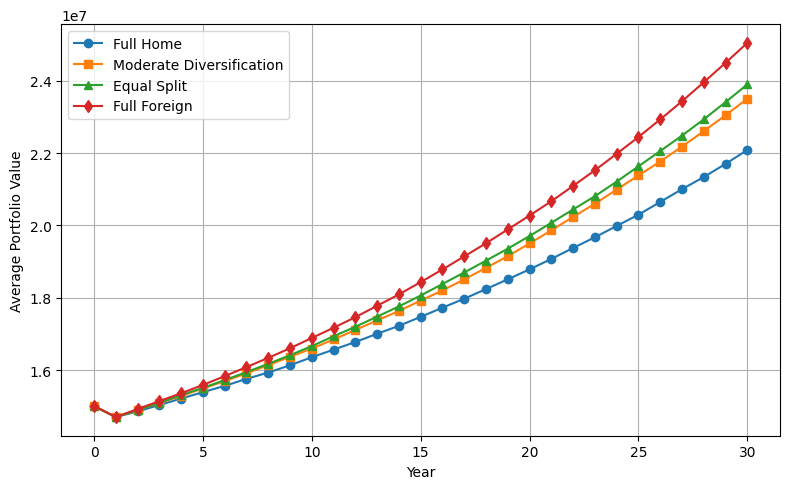

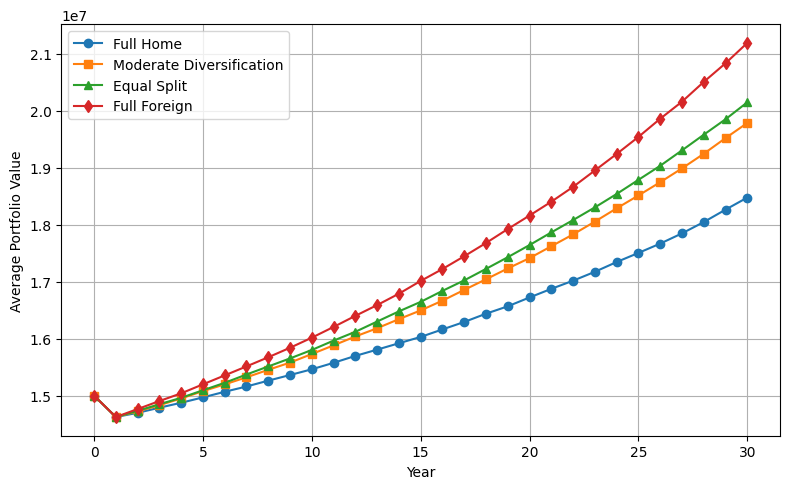

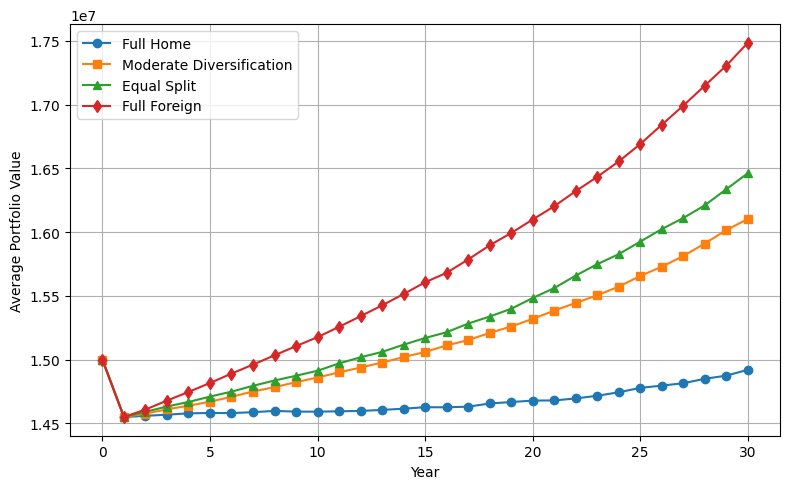

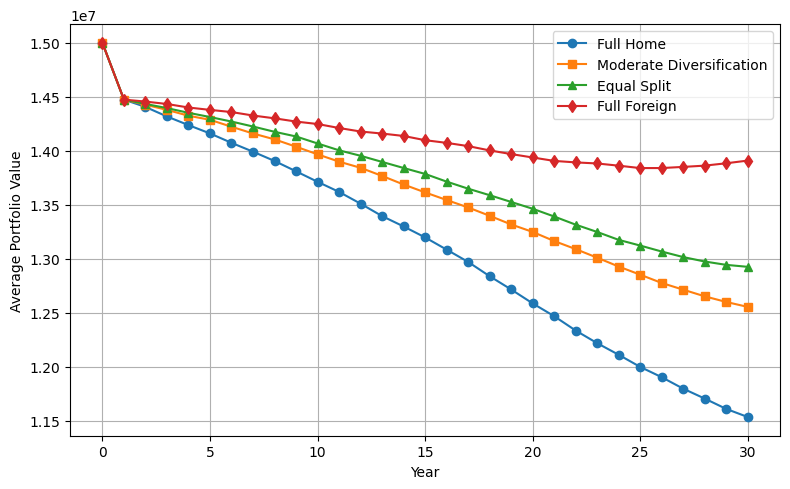

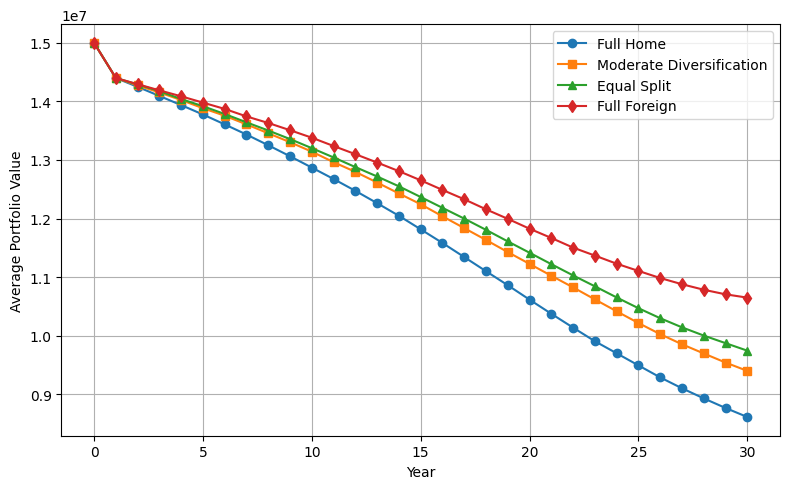

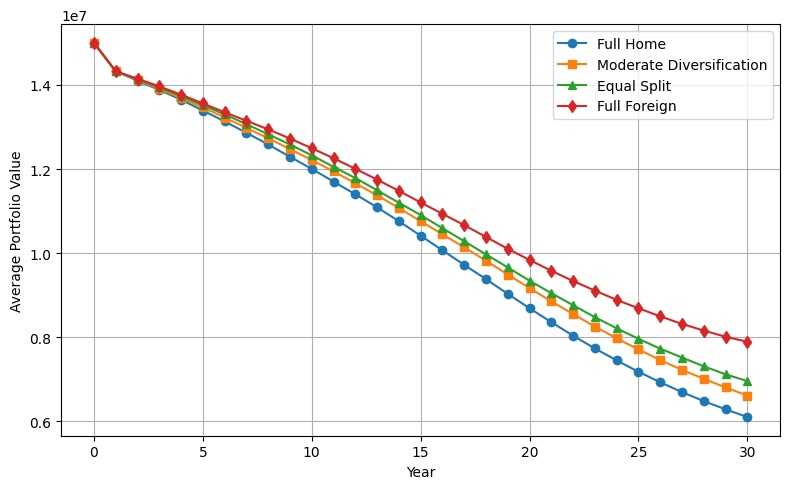

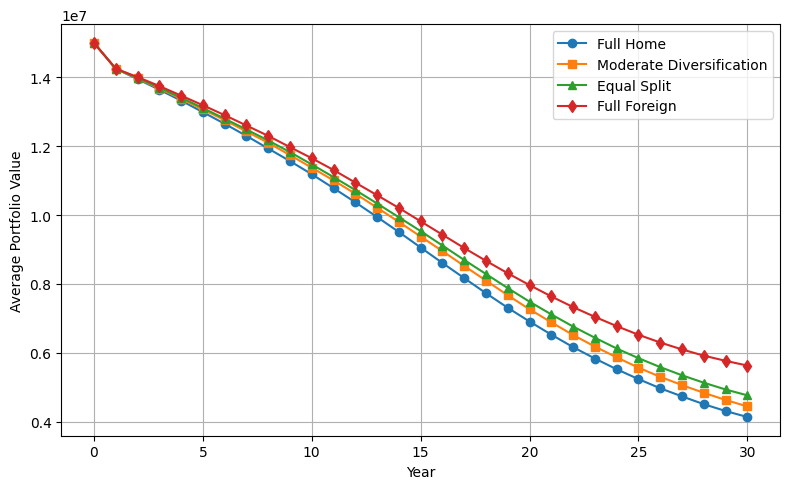

In [147]:
for name in full_home_portfolios.keys(): 
    plot_multiple_scenarios(dicts=[full_home_real, moderate_div_real, equal_split_rate, full_foreign_real], labels=['Full Home', 'Moderate Diversification', 'Equal Split', 'Full Foreign'], key=name)